# Forecasting Preparation and Baseline Experiments

**Research project:** Retrieval-Augmented Air Quality Forecasting  
**Dataset:** UCI Beijing Multi-Site Air Quality Dataset (12 stations; March 2013–February 2017)  
**Task:** One-hour-ahead PM2.5 forecasting from the previous 24 hourly PM2.5 measurements.

**Reproducibility:** Run from the repository root or from its `notebooks/` directory. Install dependencies from `requirements.txt`, download the UCI dataset to `data/raw/`, and keep `src/data_loader.py` and `src/windows.py` in the repository. Run cells in order (**Kernel → Restart Kernel and Run All Cells**). Original saved charts and results are retained where unchanged; new and modified cells should be rerun locally.

**Data protocol:** Chronological train/validation/test splits; complete 25-hour windows inside each split; missing values and gaps excluded. Validation selects models; the test split is reserved for final comparative evaluation. Earlier exploratory persistence test scores are reported as a benchmark and must not guide model selection.

## 1. Load observations and construct chronological partitions

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Find the repository regardless of where it was cloned.
# Works when Jupyter starts in the repository root or notebooks/.
cwd = Path.cwd().resolve()
if (cwd / "src" / "data_loader.py").exists():
    project_root = cwd
elif (cwd.parent / "src" / "data_loader.py").exists():
    project_root = cwd.parent
else:
    raise FileNotFoundError(
        "Open JupyterLab in the repository root or notebooks/ directory."
    )

sys.path.insert(0, str(project_root))

from src.data_loader import load_air_quality_data
from src.windows import make_windows

# The current project loader resolves data/raw relative to cwd.
# Switch to the repository root for reproducible file lookup.
import os
os.chdir(project_root)

df = load_air_quality_data()

print("Dataset shape:", df.shape)
display(df.head())

Found 12 CSV files
Loading PRSA_Data_Aotizhongxin_20130301-20170228.csv: 35064 rows
Loading PRSA_Data_Changping_20130301-20170228.csv: 35064 rows
Loading PRSA_Data_Dingling_20130301-20170228.csv: 35064 rows
Loading PRSA_Data_Dongsi_20130301-20170228.csv: 35064 rows
Loading PRSA_Data_Guanyuan_20130301-20170228.csv: 35064 rows
Loading PRSA_Data_Gucheng_20130301-20170228.csv: 35064 rows
Loading PRSA_Data_Huairou_20130301-20170228.csv: 35064 rows
Loading PRSA_Data_Nongzhanguan_20130301-20170228.csv: 35064 rows
Loading PRSA_Data_Shunyi_20130301-20170228.csv: 35064 rows
Loading PRSA_Data_Tiantan_20130301-20170228.csv: 35064 rows
Loading PRSA_Data_Wanliu_20130301-20170228.csv: 35064 rows
Loading PRSA_Data_Wanshouxigong_20130301-20170228.csv: 35064 rows
Dataset shape: (420768, 19)


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,datetime
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin,2013-03-01 00:00:00
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin,2013-03-01 01:00:00
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin,2013-03-01 02:00:00
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin,2013-03-01 03:00:00
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin,2013-03-01 04:00:00


In [2]:
# Define chronological boundaries
train_end = "2015-03-01"
val_end = "2016-03-01"

train_df = df[df["datetime"] < train_end].copy()

val_df = df[
    (df["datetime"] >= train_end)
    & (df["datetime"] < val_end)
].copy()

test_df = df[df["datetime"] >= val_end].copy()

# Validate the split
assert len(train_df) + len(val_df) + len(test_df) == len(df)

assert train_df["datetime"].max() < val_df["datetime"].min()
assert val_df["datetime"].max() < test_df["datetime"].min()

print("Training rows:", len(train_df))
print("Validation rows:", len(val_df))
print("Testing rows:", len(test_df))

Training rows: 210240
Validation rows: 105408
Testing rows: 105120


## 2. Construct next-hour forecasting windows

Each example contains **24 consecutive, finite past hourly values** from **one monitoring station**, followed by the following hour as its target. For simplicity, windows do not cross split boundaries. This discards some valid boundary contexts, but avoids any accidental inclusion of unavailable information.

In [3]:
from src.windows import make_windows

HISTORY = 24

# Training windows
X_train, y_train, stations_train, times_train = (
    make_windows(train_df, history=HISTORY)
)

# Validation windows
X_val, y_val, stations_val, times_val = (
    make_windows(val_df, history=HISTORY)
)

# Test windows
X_test, y_test, stations_test, times_test = (
    make_windows(test_df, history=HISTORY)
)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (186115, 24) (186115,)
Validation: (87373, 24) (87373,)
Testing: (86977, 24) (86977,)


In [4]:
print("Station:", stations_train[0])
print("Target time:", times_train[0])

print("\nHistorical PM2.5 values:")
print(X_train[0])

print("\nNext-hour PM2.5 target:")
print(y_train[0])

print("\nNumber of historical hours:")
print(len(X_train[0]))

Station: Aotizhongxin
Target time: 2013-03-02T00:00:00.000000000

Historical PM2.5 values:
[ 4.  8.  7.  6.  3.  5.  3.  3.  3.  3.  3.  3.  3.  3.  6.  8.  9. 10.
 11.  8. 11. 12. 15. 24.]

Next-hour PM2.5 target:
22.0

Number of historical hours:
24


In [5]:
import numpy as np

# Correct feature dimensions
assert X_train.shape[1] == 24
assert X_val.shape[1] == 24
assert X_test.shape[1] == 24

# Inputs and targets have matching sample counts
assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)

# No missing or infinite values
assert np.isfinite(X_train).all()
assert np.isfinite(y_train).all()
assert np.isfinite(X_val).all()
assert np.isfinite(y_val).all()
assert np.isfinite(X_test).all()
assert np.isfinite(y_test).all()

# Target timestamps stay inside their splits
assert (times_train < np.datetime64("2015-03-01")).all()

assert (
    (times_val >= np.datetime64("2015-03-01"))
    & (times_val < np.datetime64("2016-03-01"))
).all()

assert (times_test >= np.datetime64("2016-03-01")).all()

print("All window validation checks passed!")

All window validation checks passed!


In [6]:
total_windows = (
    len(X_train) + len(X_val) + len(X_test)
)

print(f"Original observations: {len(df):,}")
print(f"Valid forecasting windows: {total_windows:,}")

for name, original, X in [
    ("Training", train_df, X_train),
    ("Validation", val_df, X_val),
    ("Testing", test_df, X_test),
]:
    print(
        f"{name}: {len(X):,} windows "
        f"from {len(original):,} observations"
    )

Original observations: 420,768
Valid forecasting windows: 360,465
Training: 186,115 windows from 210,240 observations
Validation: 87,373 windows from 105,408 observations
Testing: 86,977 windows from 105,120 observations


### 2.1 Unit-style checks on synthetic observations

These additional checks exercise the window generator on a **small synthetic dataset** with two stations, a missing concentration and a missing timestamp. They supplement the existing array-shape assertions. The test is intentionally isolated from the real dataset and does not mutate it.

In [7]:
# Synthetic tests: station separation, hour gaps, missing PM2.5, target alignment.
start = pd.Timestamp("2020-01-01 00:00:00")
synthetic_rows = []
for station, offset in [("A", 0.0), ("B", 1000.0)]:
    for hour in range(30):
        if station == "B" and hour == 10:  # missing timestamp
            continue
        value = offset + float(hour)
        if station == "A" and hour == 12:  # missing measurement
            value = np.nan
        synthetic_rows.append({
            "station": station,
            "datetime": start + pd.Timedelta(hours=hour),
            "PM2.5": value,
        })
synthetic = pd.DataFrame(synthetic_rows)

X_s, y_s, stations_s, times_s = make_windows(synthetic, history=3)
assert X_s.shape[1] == 3
assert len(X_s) == len(y_s) == len(stations_s) == len(times_s)
assert np.isfinite(X_s).all() and np.isfinite(y_s).all()

for features, target, station, target_time in zip(X_s, y_s, stations_s, times_s):
    # Each value must be the measurement recorded at the exact preceding hour.
    target_time = pd.Timestamp(target_time)
    actual_rows = synthetic.loc[synthetic["station"] == station].set_index("datetime")
    for lag, observed in enumerate(features[::-1], start=1):
        assert observed == actual_rows.loc[target_time - pd.Timedelta(hours=lag), "PM2.5"]
    assert target == actual_rows.loc[target_time, "PM2.5"]
    # There can be no mixture of the two stations' distinct value ranges.
    assert ((features < 1000).all() and target < 1000) if station == "A" else ((features >= 1000).all() and target >= 1000)

print(f"Synthetic window checks passed: {len(y_s)} samples")

Synthetic window checks passed: 46 samples


## 3. Experiment 1 — Persistence baseline

In [8]:
import numpy as np

# Persistence: predict the last observed value
y_pred_train = X_train[:, -1]
y_pred_val = X_val[:, -1]
y_pred_test = X_test[:, -1]

print("First five predictions:")
print(y_pred_test[:5])

print("\nFirst five actual values:")
print(y_test[:5])

First five predictions:
[187. 174. 205. 206. 204.]

First five actual values:
[174. 205. 206. 204. 213.]


In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

def evaluate_forecast(y_true, y_pred):
    """Return MAE and RMSE as plain Python floats (µg/m³)."""
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return {"MAE": round(float(mae), 3), "RMSE": round(float(rmse), 3)}

print("Training:", evaluate_forecast(y_train, y_pred_train))
print("Validation:", evaluate_forecast(y_val, y_pred_val))
print("Testing (descriptive benchmark only):", evaluate_forecast(y_test, y_pred_test))

Training: {'MAE': 11.052, 'RMSE': 20.498}
Validation: {'MAE': 9.785, 'RMSE': 19.059}
Testing (descriptive benchmark only): {'MAE': 10.136, 'RMSE': 19.514}


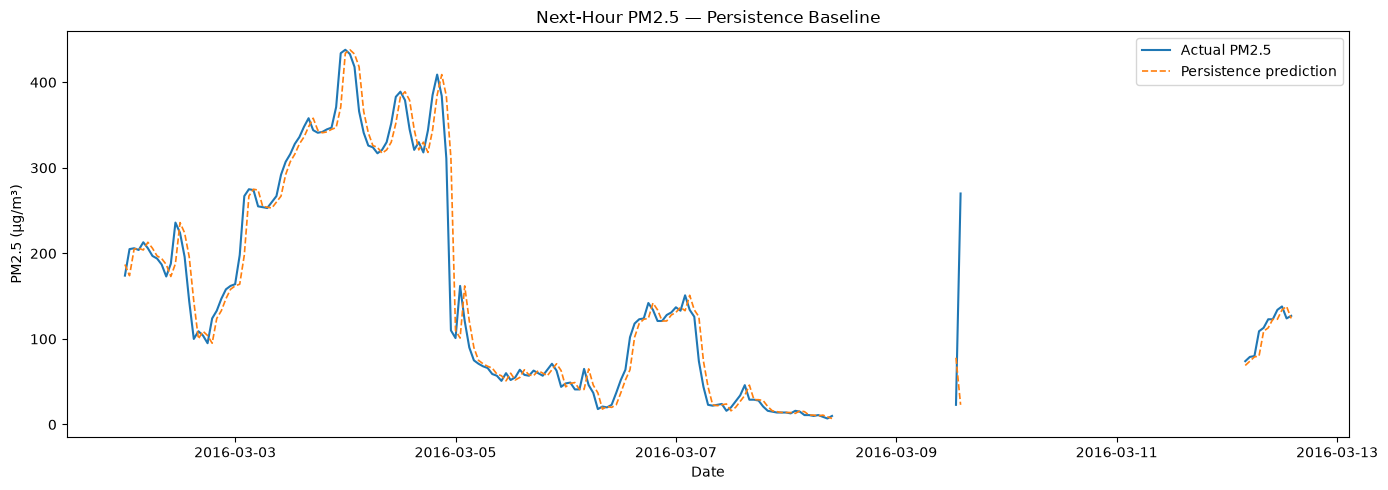

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

station_name = "Aotizhongxin"

mask = stations_test == station_name

plot_df = pd.DataFrame({
    "datetime": pd.to_datetime(times_test[mask]),
    "actual": y_test[mask],
    "predicted": y_pred_test[mask]
})

# Take the first 168 valid prediction samples
plot_df = (
    plot_df.sort_values("datetime")
    .head(168)
    .set_index("datetime")
)

# Reindex to the complete hourly timeline.
# Missing timestamps become NaN, creating line breaks.
hourly_index = pd.date_range(
    start=plot_df.index.min(),
    end=plot_df.index.max(),
    freq="h"
)

plot_df = plot_df.reindex(hourly_index)

plt.figure(figsize=(14, 5))

plt.plot(
    plot_df.index,
    plot_df["actual"],
    label="Actual PM2.5",
    linewidth=1.5
)

plt.plot(
    plot_df.index,
    plot_df["predicted"],
    label="Persistence prediction",
    linestyle="--",
    linewidth=1.2
)

plt.title("Next-Hour PM2.5 — Persistence Baseline")
plt.xlabel("Date")
plt.ylabel("PM2.5 (µg/m³)")
plt.legend()
plt.tight_layout()
plt.show()

### Persistence Forecast Visualization — Interpretation

The persistence forecasting model generally follows gradual changes in hourly PM2.5 concentrations but exhibits a one-hour lag during rapid concentration increases and decreases.

The visualization was adjusted to preserve missing timestamps using hourly reindexing, preventing misleading lines from connecting observations across data gaps.

Sharp concentration changes appear to be important sources of forecasting error.

**Research implication:** More advanced forecasting methods should be evaluated on their ability to predict rapid concentration changes rather than only matching stable pollution periods.

In [11]:
import pandas as pd

station_results = []

for station in np.unique(stations_test):

    mask = stations_test == station

    metrics = evaluate_forecast(
        y_test[mask],
        y_pred_test[mask]
    )

    station_results.append({
        "station": station,
        "samples": mask.sum(),
        **metrics
    })

station_results = pd.DataFrame(station_results)

display(
    station_results.sort_values(
        "MAE",
        ascending=False
    )
)

,station,samples,MAE,RMSE
11,Wanshouxigong,7361,11.298,22.873
3,Dongsi,6838,11.070,21.399
8,Shunyi,6593,10.856,20.792
4,Guanyuan,7371,10.605,18.902
9,Tiantan,7499,10.555,18.815
0,Aotizhongxin,7358,10.464,19.642
7,Nongzhanguan,7314,10.283,19.199
5,Gucheng,7284,10.160,20.144
10,Wanliu,7562,9.778,18.584
1,Changping,7313,9.657,18.062


### Experiment 1 — Persistence Forecasting Baseline

**Objective:** Establish a simple benchmark for one-hour-ahead PM2.5 forecasting using the most recent observed concentration.

**Method:** A persistence forecast predicts that the next hourly PM2.5 concentration will equal the final value in a 24-hour historical input window.

**Dataset:** Twelve Beijing air-quality monitoring stations, with chronological training, validation, and testing partitions. Only windows containing consecutive hourly timestamps and finite PM2.5 observations were evaluated.

**Results:**

| Dataset | MAE (µg/m³) | RMSE (µg/m³) |
|---|---:|---:|
| Training | 11.052 | 20.498 |
| Validation | 9.785 | 19.059 |
| Testing | 10.136 | 19.514 |

Station-level test MAE ranges from 8.475 µg/m³ at Dingling to 11.298 µg/m³ at Wanshouxigong.

**Interpretation:** Persistence provides a useful benchmark for next-hour forecasting. The difference between MAE and RMSE indicates that relatively large forecast errors contribute substantially to squared-error loss.

**Limitations:** Persistence cannot anticipate abrupt changes in concentration. The evaluation excludes windows containing missing PM2.5 values, and results may not represent performance during sensor outages. More complex methods must be compared using consistent evaluation samples.

**Next experiment:** Train a regression model using the previous 24 hours of PM2.5 measurements and compare its validation performance with persistence.

## 4. Experiment 2 — Ridge Regression versus persistence

In [12]:
from sklearn.linear_model import Ridge

ridge_model = Ridge(alpha=10.0)

ridge_model.fit(X_train, y_train)

# Generate validation predictions
ridge_val_pred = ridge_model.predict(X_val)

print("Ridge Regression — Validation")
print(evaluate_forecast(y_val, ridge_val_pred))

print("\nPersistence — Validation")
print(evaluate_forecast(y_val, y_pred_val))

Ridge Regression — Validation
{'MAE': 9.677, 'RMSE': 18.274}

Persistence — Validation
{'MAE': 9.785, 'RMSE': 19.059}


In [13]:
comparison = pd.DataFrame([
    {
        "Model": "Persistence",
        **evaluate_forecast(y_val, y_pred_val)
    },
    {
        "Model": "Ridge Regression",
        **evaluate_forecast(y_val, ridge_val_pred)
    }
])

display(comparison)

,Model,MAE,RMSE
0,Persistence,9.785,19.059
1,Ridge Regression,9.677,18.274


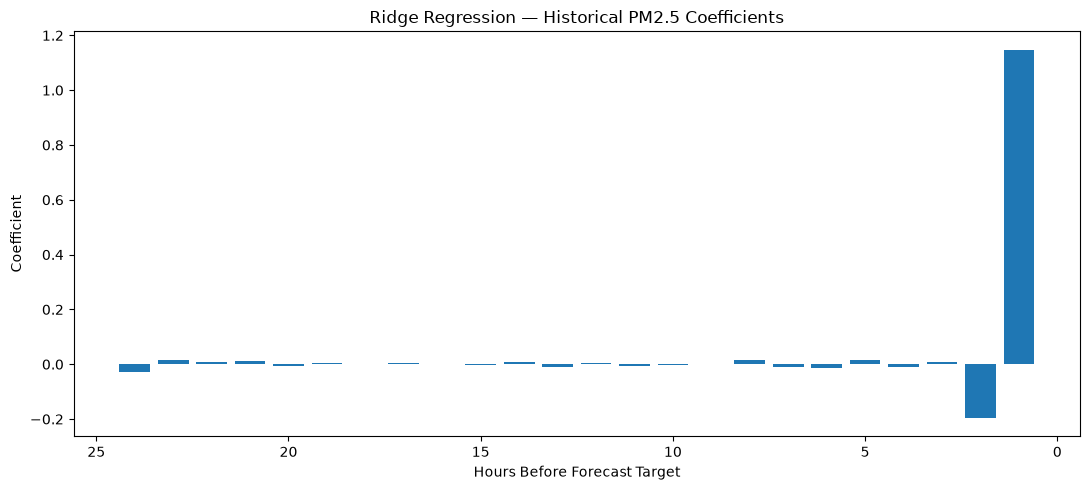

Intercept: 3.142


In [14]:
import numpy as np
import matplotlib.pyplot as plt

lags = np.arange(24, 0, -1)

plt.figure(figsize=(11, 5))

plt.bar(lags, ridge_model.coef_)

plt.title("Ridge Regression — Historical PM2.5 Coefficients")
plt.xlabel("Hours Before Forecast Target")
plt.ylabel("Coefficient")

plt.gca().invert_xaxis()
plt.tight_layout()
plt.show()

print("Intercept:", round(float(ridge_model.intercept_), 3))

In [15]:
persistence_mae = evaluate_forecast(
    y_val, y_pred_val
)["MAE"]

ridge_mae = evaluate_forecast(
    y_val, ridge_val_pred
)["MAE"]

improvement = (
    (persistence_mae - ridge_mae)
    / persistence_mae
    * 100
)

print(f"Ridge MAE improvement: {improvement:.2f}%")

Ridge MAE improvement: 1.10%


### Ridge validation findings

**Model:** Ridge Regression, `alpha=10.0`; fitted on the training split only.

| Model | Validation MAE (µg/m³) | Validation RMSE (µg/m³) |
|---|---:|---:|
| Persistence | 9.785 | 19.059 |
| Ridge Regression | 9.677 | 18.274 |

Ridge improves validation MAE by approximately **1.10%** and RMSE by approximately **4.12%** relative to persistence. Its coefficients emphasize the latest observations, but correlated lags make individual coefficients hard to interpret causally.

**Caveats:** One validation interval does not establish statistical significance or robustness. The test period is not used to select Ridge hyperparameters.

## 5. Experiment 3 — Ridge regularization sensitivity

In [16]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

alphas = [0.1, 1, 10, 100, 1000, 10000]

results = []

for alpha in alphas:

    model = Ridge(alpha=alpha)
    model.fit(X_train, y_train)

    predictions = model.predict(X_val)

    mae = mean_absolute_error(y_val, predictions)
    rmse = np.sqrt(mean_squared_error(y_val, predictions))

    results.append({
        "alpha": alpha,
        "MAE": mae,
        "RMSE": rmse
    })

tuning_results = pd.DataFrame(results)

display(tuning_results.round(4))

,alpha,MAE,RMSE
0,0.1,9.6772,18.2740
1,1.0,9.6772,18.2740
2,10.0,9.6772,18.2740
3,100.0,9.6772,18.2740
4,1000.0,9.6773,18.2740
5,10000.0,9.6774,18.2743


In [17]:
best_row = tuning_results.loc[
    tuning_results["MAE"].idxmin()
]

best_alpha = best_row["alpha"]

print(f"Best alpha: {best_alpha}")
print(f"Validation MAE: {best_row['MAE']:.4f}")
print(f"Validation RMSE: {best_row['RMSE']:.4f}")

Best alpha: 0.1
Validation MAE: 9.6772
Validation RMSE: 18.2740


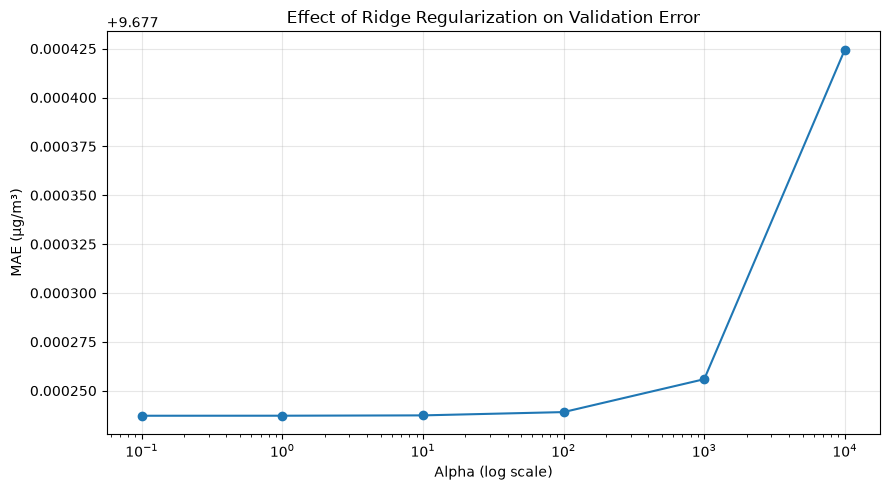

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    tuning_results["alpha"],
    tuning_results["MAE"],
    marker="o",
    label="Validation MAE"
)

plt.xscale("log")

plt.title("Effect of Ridge Regularization on Validation Error")
plt.xlabel("Alpha (log scale)")
plt.ylabel("MAE (µg/m³)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Regularization sensitivity — Research notes

**Question:** How much does the Ridge penalty affect one-hour-ahead forecasting accuracy?

**Method:** The following regularization parameters were evaluated using the same training and validation examples: `0.1`, `1`, `10`, `100`, `1000`, and `10000`. The selection criterion was validation **MAE**, not the test error.

**Saved result:** All evaluated settings produced nearly identical validation scores: MAE approximately **9.6772–9.6774 µg/m³** and RMSE approximately **18.2740–18.2743 µg/m³**. The lowest measured MAE among these candidates was at `alpha=0.1`, but the numerical differences are negligible at this precision. Therefore, we should not claim material improvement from tuning.

**Research interpretation:** Model performance is not particularly sensitive to alpha over this candidate range. More robust conclusions would require rolling-origin validation and evaluation of additional forecasting methods.

**Test-set discipline:** The persistence test result is retained from earlier exploration for transparency; **do not** use it to choose Ridge hyperparameters or subsequent model designs.

## 6. Reproduction and next experiments

- **Required project files:** `src/data_loader.py`, `src/windows.py`, this notebook, and `requirements.txt`.
- **Dataset:** The UCI Beijing Multi-Site Air Quality CSVs must be extracted beneath `data/raw/` (raw data is excluded from Git).
- **Target:** PM2.5 at the next hour, using 24 hours of past PM2.5 from the same station.
- **Validation discipline:** Use validation for model selection; reserve test data for the final selected comparison.
- **Planned follow-up:** Rolling-origin validation; nonlinear baseline such as gradient boosting; weather features with training-only preprocessing; and controlled retrieval-augmented comparisons.

> **Important:** These are saved experimental results, not independently rerun outputs. After replacing the local notebook, choose **Kernel → Restart Kernel and Run All Cells** to reproduce them on your Mac. Any new validation checks will show outputs only after execution.